In [1]:
# MGS 670 Project 1: Complete preprocessing, descriptive statistics, MLP and sequential RNN modeling for Hospital Length of Stay prediction.

import numpy as np
import pandas as pd
import json
import ast
import re
import warnings
import tensorflow as tf

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, Dense, TimeDistributed

warnings.filterwarnings("ignore")
np.random.seed(42)
tf.random.set_seed(42)

print("=" * 70)
print("MGS 670 PROJECT 1")
print("=" * 70)

print("\nUpload Canada_Hosp1_COVID_InpatientData.xlsx")
uploaded = files.upload()

file_path = next(iter(uploaded.keys()))

admission_df = pd.read_excel(file_path, sheet_name="Data-at-admission")
days_df = pd.read_excel(file_path, sheet_name="Days-breakdown")
hlos_df = pd.read_excel(file_path, sheet_name="Hospital-length-of-stay")
medication_df = pd.read_excel(file_path, sheet_name="Medication-Static-List")

print("\nDATA LOADED")
print("Data-at-admission:", admission_df.shape)
print("Days-breakdown:", days_df.shape)
print("Hospital-length-of-stay:", hlos_df.shape)
print("Medication-Static-List:", medication_df.shape)

required_features = [
    'age',
    'sex',
    'height',
    'weight',
    'comorbidities',
    'systolic_blood_pressure',
    'diastolic_blood_pressure',
    'heart_rate',
    'respiratory_rate',
    'oxygen_saturation',
    'temperature',
    'motor',
    'verbal',
    'eye',
    'wbc',
    'rbc',
    'hemoglobin',
    'hematocrit',
    'mcv',
    'mch',
    'mchc',
    'rdw',
    'platelet_count',
    'aptt_aptr',
    'pt',
    'alt',
    'ast',
    'serum_creatinine',
    'sodium',
    'potassium',
    'total_serum_bilirubin',
    'lactate',
    'pao2',
    'pao2_fio2',
    'ph',
    'high_senstivity_cardiac_troponin',
    'esr',
    'inr',
    'ferritin',
    'd_dimer',
    'crp',
    'hs_crp',
    'intubated'
]

available_features = [c for c in required_features if c in admission_df.columns]
missing_required = [c for c in required_features if c not in admission_df.columns]

print("\n" + "=" * 70)
print("REQUIRED FEATURES")
print("=" * 70)
print("Requested:", len(required_features))
print("Available:", len(available_features))
print("Not found:", missing_required)

mlp_df = admission_df[['id'] + available_features].copy()

mlp_df = mlp_df.merge(
    hlos_df[['parent_id', 'hospital_length_of_stay']],
    left_on='id',
    right_on='parent_id',
    how='inner'
)

mlp_df.drop(columns=['parent_id'], inplace=True)

all_missing_mlp = [
    c for c in available_features
    if mlp_df[c].isna().all()
]

print("\nCompletely missing admission columns:", all_missing_mlp)

mlp_df.drop(columns=all_missing_mlp, inplace=True)

def clean_numeric_series(series):
    return pd.to_numeric(
        series.astype(str)
        .str.replace('<', '', regex=False)
        .str.replace('>', '', regex=False)
        .str.strip()
        .replace({
            'nan': np.nan,
            'None': np.nan,
            '': np.nan
        }),
        errors='coerce'
    )

for col in ['d_dimer', 'aptt_aptr']:
    if col in mlp_df.columns:
        mlp_df[col] = clean_numeric_series(mlp_df[col])

if 'sex' in mlp_df.columns:
    mlp_df['sex'] = (
        mlp_df['sex']
        .astype(str)
        .str.strip()
        .str.lower()
        .map({'female': 0, 'male': 1})
    )

if 'intubated' in mlp_df.columns:
    mlp_df['intubated'] = (
        mlp_df['intubated']
        .astype(str)
        .str.strip()
        .str.lower()
        .map({'no': 0, 'yes': 1})
    )

def parse_comorbidities(value):
    if pd.isna(value):
        return []
    obj = value
    for _ in range(3):
        if isinstance(obj, str):
            s = obj.strip()
            try:
                obj = json.loads(s)
                continue
            except:
                try:
                    obj = ast.literal_eval(s)
                    continue
                except:
                    break
        break
    if isinstance(obj, list):
        return [str(x).strip() for x in obj if str(x).strip()]
    if isinstance(obj, dict):
        return [str(k).strip() for k, v in obj.items() if bool(v)]
    s = str(obj).strip()
    if s.lower() in ['', 'nan', 'none', '[]', '{}']:
        return []
    parts = re.split(r'[;,|]', s)
    return [p.strip(" []'\"") for p in parts if p.strip(" []'\"")]

if 'comorbidities' in mlp_df.columns:
    parsed_comorbidities = mlp_df['comorbidities'].apply(parse_comorbidities)
    comorbidity_categories = sorted({
        item
        for row in parsed_comorbidities
        for item in row
    })
    for category in comorbidity_categories:
        mlp_df['comorbidity_' + category] = parsed_comorbidities.apply(
            lambda x: int(category in x)
        )
    mlp_df.drop(columns=['comorbidities'], inplace=True)
else:
    comorbidity_categories = []

for col in mlp_df.columns:
    if col not in ['id', 'hospital_length_of_stay']:
        mlp_df[col] = pd.to_numeric(mlp_df[col], errors='coerce')

predictor_cols_mlp = [
    c for c in mlp_df.columns
    if c not in ['id', 'hospital_length_of_stay']
]

missing_fraction_mlp = mlp_df[predictor_cols_mlp].isna().mean()

high_missing_mlp = missing_fraction_mlp[
    missing_fraction_mlp > 0.90
].index.tolist()

mlp_df.drop(columns=high_missing_mlp, inplace=True)

predictor_cols_mlp = [
    c for c in mlp_df.columns
    if c not in ['id', 'hospital_length_of_stay']
]

all_zero_mlp = [
    c for c in predictor_cols_mlp
    if mlp_df[c].notna().any()
    and (mlp_df[c].fillna(0) == 0).all()
]

print("\n" + "=" * 70)
print("DATA-AT-ADMISSION DESCRIPTIVE RESULTS")
print("=" * 70)
print("Patients:", mlp_df.shape[0])
print("Predictor columns after preprocessing:", len(predictor_cols_mlp))
print("Columns removed for >90% missingness:", high_missing_mlp)
print("Number of all-zero predictor columns:", len(all_zero_mlp))
print("All-zero predictor columns:", all_zero_mlp)

print("\nMEAN OF EACH PREPROCESSED ADMISSION FEATURE")
admission_means = mlp_df[predictor_cols_mlp].mean(numeric_only=True)
print(admission_means.round(3).to_string())

print("\nHLOS SUMMARY")
print(mlp_df['hospital_length_of_stay'].describe().round(3).to_string())

X_mlp_raw = mlp_df[predictor_cols_mlp].copy()
y_mlp = mlp_df['hospital_length_of_stay'].astype(float).copy()

X_mlp_train_raw, X_mlp_test_raw, y_mlp_train, y_mlp_test = train_test_split(
    X_mlp_raw,
    y_mlp,
    test_size=0.20,
    random_state=42
)

mlp_imputer = SimpleImputer(strategy='median')

X_mlp_train_imputed = mlp_imputer.fit_transform(X_mlp_train_raw)
X_mlp_test_imputed = mlp_imputer.transform(X_mlp_test_raw)

mlp_scaler = StandardScaler()

X_mlp_train = mlp_scaler.fit_transform(X_mlp_train_imputed)
X_mlp_test = mlp_scaler.transform(X_mlp_test_imputed)

print("\n" + "=" * 70)
print("MLP TRAIN/TEST SPLIT")
print("=" * 70)
print("Training patients:", X_mlp_train.shape[0])
print("Testing patients:", X_mlp_test.shape[0])
print("Predictors:", X_mlp_train.shape[1])

mlp_configs = [
    {
        'name': 'Baseline MLP',
        'hidden_layer_sizes': (64, 32),
        'alpha': 0.0001,
        'learning_rate_init': 0.001
    },
    {
        'name': 'Smaller MLP',
        'hidden_layer_sizes': (16,),
        'alpha': 0.0001,
        'learning_rate_init': 0.001
    },
    {
        'name': 'Regularized MLP',
        'hidden_layer_sizes': (64, 32),
        'alpha': 0.01,
        'learning_rate_init': 0.001
    },
    {
        'name': 'Lower Learning Rate MLP',
        'hidden_layer_sizes': (64, 32),
        'alpha': 0.0001,
        'learning_rate_init': 0.0001
    }
]

mlp_results_list = []

for config in mlp_configs:

    model = MLPRegressor(
        hidden_layer_sizes=config['hidden_layer_sizes'],
        activation='relu',
        solver='adam',
        alpha=config['alpha'],
        learning_rate_init=config['learning_rate_init'],
        max_iter=1000,
        random_state=42
    )

    model.fit(X_mlp_train, y_mlp_train)

    train_pred = model.predict(X_mlp_train)
    test_pred = model.predict(X_mlp_test)

    train_mse = mean_squared_error(y_mlp_train, train_pred)
    test_mse = mean_squared_error(y_mlp_test, test_pred)

    mlp_results_list.append({
        'Model': config['name'],
        'Train MSE': train_mse,
        'Test MSE': test_mse,
        'Train RMSE': np.sqrt(train_mse),
        'Test RMSE': np.sqrt(test_mse),
        'Iterations': model.n_iter_
    })

mlp_results = pd.DataFrame(mlp_results_list)

print("\n" + "=" * 70)
print("MLP RESULTS")
print("=" * 70)
print(mlp_results.round(3).to_string(index=False))

days = days_df.copy()

def find_daily_source(df, base):
    if base in df.columns:
        return ('direct', [base])

    candidates = [
        c for c in df.columns
        if c.lower() in [
            'highest_' + base.lower(),
            'lowest_' + base.lower(),
            'maximum_' + base.lower(),
            'minimum_' + base.lower(),
            'max_' + base.lower(),
            'min_' + base.lower()
        ]
    ]

    if len(candidates) > 0:
        return ('aggregate', candidates)

    contains = [
        c for c in df.columns
        if base.lower() in c.lower()
        and c not in ['id', 'parent_id', 'day']
    ]

    numeric_like = [
        c for c in contains
        if not any(
            word in c.lower()
            for word in ['finding', 'time', 'date']
        )
    ]

    if len(numeric_like) > 0:
        return ('aggregate', numeric_like)

    return (None, [])

rnn_base_features = [
    c for c in required_features
    if c not in ['comorbidities']
]

rnn_work = days[['id', 'parent_id', 'day']].copy()
rnn_sources = {}

for base in rnn_base_features:
    mode, source_cols = find_daily_source(days, base)

    if mode == 'direct':
        rnn_work[base] = days[source_cols[0]]
        rnn_sources[base] = source_cols

    elif mode == 'aggregate':
        temp = days[source_cols].copy()
        for c in source_cols:
            temp[c] = pd.to_numeric(temp[c], errors='coerce')
        rnn_work[base] = temp.mean(axis=1)
        rnn_sources[base] = source_cols

static_candidates = [
    'age',
    'sex',
    'height',
    'weight',
    'intubated'
]

admission_static = admission_df[['id']].copy()

for c in static_candidates:
    if c in admission_df.columns and c not in rnn_work.columns:
        admission_static[c] = admission_df[c]

admission_static = admission_static.rename(columns={'id': 'parent_id'})

for c in admission_static.columns:
    if c != 'parent_id' and c not in rnn_work.columns:
        rnn_work = rnn_work.merge(
            admission_static[['parent_id', c]],
            on='parent_id',
            how='left'
        )

if 'sex' in rnn_work.columns:
    rnn_work['sex'] = (
        rnn_work['sex']
        .astype(str)
        .str.strip()
        .str.lower()
        .map({'female': 0, 'male': 1})
    )

if 'intubated' in rnn_work.columns:
    rnn_work['intubated'] = (
        rnn_work['intubated']
        .astype(str)
        .str.strip()
        .str.lower()
        .map({'no': 0, 'yes': 1})
    )

for col in rnn_work.columns:
    if col not in ['id', 'parent_id', 'day']:
        if rnn_work[col].dtype == 'object':
            rnn_work[col] = clean_numeric_series(rnn_work[col])
        else:
            rnn_work[col] = pd.to_numeric(
                rnn_work[col],
                errors='coerce'
            )

rnn_feature_cols = [
    c for c in rnn_work.columns
    if c not in ['id', 'parent_id', 'day']
]

rnn_all_missing = [
    c for c in rnn_feature_cols
    if rnn_work[c].isna().all()
]

rnn_work.drop(columns=rnn_all_missing, inplace=True)

rnn_feature_cols = [
    c for c in rnn_work.columns
    if c not in ['id', 'parent_id', 'day']
]

rnn_missing_fraction = rnn_work[rnn_feature_cols].isna().mean()

rnn_high_missing = rnn_missing_fraction[
    rnn_missing_fraction > 0.90
].index.tolist()

rnn_work.drop(columns=rnn_high_missing, inplace=True)

rnn_feature_cols = [
    c for c in rnn_work.columns
    if c not in ['id', 'parent_id', 'day']
]

rnn_all_zero = [
    c for c in rnn_feature_cols
    if rnn_work[c].notna().any()
    and (rnn_work[c].fillna(0) == 0).all()
]

print("\n" + "=" * 70)
print("DAYS-BREAKDOWN DESCRIPTIVE RESULTS")
print("=" * 70)
print("Daily records:", rnn_work.shape[0])
print("Patients:", rnn_work['parent_id'].nunique())
print("RNN predictor features:", len(rnn_feature_cols))
print("Completely missing RNN columns removed:", rnn_all_missing)
print("RNN columns removed for >90% missingness:", rnn_high_missing)
print("Number of all-zero RNN columns:", len(rnn_all_zero))
print("All-zero RNN columns:", rnn_all_zero)

print("\nMEAN OF EACH PREPROCESSED DAYS-BREAKDOWN FEATURE")
print(
    rnn_work[rnn_feature_cols]
    .mean(numeric_only=True)
    .round(3)
    .to_string()
)

hlos_map = (
    hlos_df
    .set_index('parent_id')['hospital_length_of_stay']
    .to_dict()
)

patient_ids = sorted(
    set(rnn_work['parent_id'].dropna().unique())
    .intersection(set(hlos_map.keys()))
)

train_patient_ids, test_patient_ids = train_test_split(
    patient_ids,
    test_size=0.20,
    random_state=42
)

train_mask = rnn_work['parent_id'].isin(train_patient_ids)
test_mask = rnn_work['parent_id'].isin(test_patient_ids)

rnn_imputer = SimpleImputer(strategy='median')

rnn_imputer.fit(
    rnn_work.loc[train_mask, rnn_feature_cols]
)

rnn_work.loc[:, rnn_feature_cols] = rnn_imputer.transform(
    rnn_work[rnn_feature_cols]
)

rnn_scaler = StandardScaler()

rnn_scaler.fit(
    rnn_work.loc[train_mask, rnn_feature_cols]
)

rnn_work.loc[:, rnn_feature_cols] = rnn_scaler.transform(
    rnn_work[rnn_feature_cols]
)

sequence_lengths = (
    rnn_work
    .groupby('parent_id')
    .size()
)

sequence_length = int(sequence_lengths.mode().iloc[0])

X_train_sequences = []
y_train_sequences = []
X_test_sequences = []
y_test_sequences = []

for patient_id in patient_ids:

    group = (
        rnn_work[rnn_work['parent_id'] == patient_id]
        .sort_values('day')
    )

    if len(group) != sequence_length:
        continue

    H = float(hlos_map[patient_id])

    X_seq = group[rnn_feature_cols].to_numpy(dtype=np.float32)

    y_seq = np.maximum(
        H - group['day'].to_numpy(dtype=np.float32),
        0
    )

    if patient_id in train_patient_ids:
        X_train_sequences.append(X_seq)
        y_train_sequences.append(y_seq)

    elif patient_id in test_patient_ids:
        X_test_sequences.append(X_seq)
        y_test_sequences.append(y_seq)

X_rnn_train = np.array(
    X_train_sequences,
    dtype=np.float32
)

X_rnn_test = np.array(
    X_test_sequences,
    dtype=np.float32
)

y_rnn_train = np.array(
    y_train_sequences,
    dtype=np.float32
)

y_rnn_test = np.array(
    y_test_sequences,
    dtype=np.float32
)

print("\n" + "=" * 70)
print("RNN TRAIN/TEST DATA")
print("=" * 70)
print("Sequence length:", sequence_length)
print("Number of RNN features:", len(rnn_feature_cols))
print("X train:", X_rnn_train.shape)
print("X test:", X_rnn_test.shape)
print("y train:", y_rnn_train.shape)
print("y test:", y_rnn_test.shape)

if len(X_rnn_train) > 0:
    example_train_patient = [
        p for p in train_patient_ids
        if len(rnn_work[rnn_work['parent_id'] == p]) == sequence_length
    ][0]

    example_group = (
        days_df[days_df['parent_id'] == example_train_patient]
        .sort_values('day')
    )

    print("\nExample patient:", example_train_patient)
    print("Recorded days:", example_group['day'].to_numpy())
    print(
        "Remaining-HLOS targets:",
        y_rnn_train[0]
    )

y_rnn_train_3d = y_rnn_train[..., np.newaxis]
y_rnn_test_3d = y_rnn_test[..., np.newaxis]

def train_rnn_model(units, name):

    tf.keras.backend.clear_session()
    tf.random.set_seed(42)

    model = Sequential([
        Input(
            shape=(
                X_rnn_train.shape[1],
                X_rnn_train.shape[2]
            )
        ),
        SimpleRNN(
            units,
            activation='tanh',
            return_sequences=True
        ),
        TimeDistributed(Dense(1))
    ])

    model.compile(
        optimizer='adam',
        loss='mse'
    )

    history = model.fit(
        X_rnn_train,
        y_rnn_train_3d,
        epochs=100,
        batch_size=32,
        validation_split=0.20,
        verbose=0
    )

    train_pred = model.predict(
        X_rnn_train,
        verbose=0
    ).squeeze(-1)

    test_pred = model.predict(
        X_rnn_test,
        verbose=0
    ).squeeze(-1)

    train_mse = mean_squared_error(
        y_rnn_train.flatten(),
        train_pred.flatten()
    )

    test_mse = mean_squared_error(
        y_rnn_test.flatten(),
        test_pred.flatten()
    )

    return {
        'Model': name,
        'Units': units,
        'Train MSE': train_mse,
        'Test MSE': test_mse,
        'Train RMSE': np.sqrt(train_mse),
        'Test RMSE': np.sqrt(test_mse),
        'Validation MSE': history.history['val_loss'][-1]
    }

rnn_results_list = []

rnn_results_list.append(
    train_rnn_model(
        32,
        'Baseline RNN'
    )
)

rnn_results_list.append(
    train_rnn_model(
        16,
        'Smaller RNN'
    )
)

rnn_results = pd.DataFrame(rnn_results_list)

print("\n" + "=" * 70)
print("RNN RESULTS")
print("=" * 70)
print(rnn_results.round(3).to_string(index=False))

best_mlp_row = mlp_results.loc[
    mlp_results['Test MSE'].idxmin()
]

best_rnn_row = rnn_results.loc[
    rnn_results['Test MSE'].idxmin()
]

print("\n" + "=" * 70)
print("FINAL MODEL RESULTS FOR REPORT")
print("=" * 70)

print("\nMLP RESULTS")
print(
    mlp_results[
        [
            'Model',
            'Train MSE',
            'Test MSE',
            'Train RMSE',
            'Test RMSE'
        ]
    ].round(3).to_string(index=False)
)

print("\nRNN RESULTS")
print(
    rnn_results[
        [
            'Model',
            'Train MSE',
            'Test MSE',
            'Train RMSE',
            'Test RMSE'
        ]
    ].round(3).to_string(index=False)
)

print("\nLowest observed MLP test MSE configuration:")
print(best_mlp_row['Model'])
print("Test MSE:", round(best_mlp_row['Test MSE'], 3))
print("Test RMSE:", round(best_mlp_row['Test RMSE'], 3))

print("\nLowest observed RNN test MSE configuration:")
print(best_rnn_row['Model'])
print("Test MSE:", round(best_rnn_row['Test MSE'], 3))
print("Test RMSE:", round(best_rnn_row['Test RMSE'], 3))

print("\n" + "=" * 70)
print("IMPORTANT FEATURES DISCUSSION")
print("=" * 70)

print(
    "Age and comorbidities may reflect baseline patient risk; vital signs such as "
    "blood pressure, heart rate, respiratory rate, oxygen saturation and temperature "
    "may reflect acute physiological instability; laboratory measurements such as "
    "WBC, hemoglobin, creatinine, electrolytes, liver markers and inflammatory markers "
    "may reflect disease severity and organ dysfunction. Intubation may indicate severe "
    "respiratory illness. These variables are therefore clinically plausible contributors "
    "to variation in hospital length of stay."
)

print("\n" + "=" * 70)
print("PROJECT RUN COMPLETED SUCCESSFULLY")
print("=" * 70)

MGS 670 PROJECT 1

Upload Canada_Hosp1_COVID_InpatientData.xlsx


Saving Canada_Hosp1_COVID_InpatientData.xlsx to Canada_Hosp1_COVID_InpatientData (1).xlsx

DATA LOADED
Data-at-admission: (508, 55)
Days-breakdown: (4064, 70)
Hospital-length-of-stay: (508, 11)
Medication-Static-List: (31254, 2)

REQUIRED FEATURES
Requested: 43
Available: 43
Not found: []

Completely missing admission columns: ['high_senstivity_cardiac_troponin', 'hs_crp']

DATA-AT-ADMISSION DESCRIPTIVE RESULTS
Patients: 508
Predictor columns after preprocessing: 53
Columns removed for >90% missingness: ['pao2', 'pao2_fio2', 'ph', 'esr', 'ferritin']
Number of all-zero predictor columns: 0
All-zero predictor columns: []

MEAN OF EACH PREPROCESSED ADMISSION FEATURE
age                                                         66.028
sex                                                          0.583
height                                                     166.911
weight                                                      80.266
systolic_blood_pressure                                    1

In [2]:
# MGS 670 Project 1: Five-trial evaluation for MLP and RNN with average and standard deviation of training MSE.

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, Dense, TimeDistributed

trial_seeds = [1, 2, 3, 4, 5]

mlp_trial_results = []

for trial, seed in enumerate(trial_seeds, start=1):

    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X_mlp_raw,
        y_mlp,
        test_size=0.20,
        random_state=seed
    )

    imputer = SimpleImputer(strategy='median')

    X_train_imp = imputer.fit_transform(X_train_raw)
    X_test_imp = imputer.transform(X_test_raw)

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train_imp)
    X_test_scaled = scaler.transform(X_test_imp)

    model = MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        learning_rate_init=0.001,
        max_iter=1000,
        random_state=seed
    )

    model.fit(X_train_scaled, y_train)

    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)

    train_mse = mean_squared_error(y_train, train_pred)
    test_mse = mean_squared_error(y_test, test_pred)

    mlp_trial_results.append({
        'Trial': trial,
        'Seed': seed,
        'Train MSE': train_mse,
        'Test MSE': test_mse
    })

mlp_trials_df = pd.DataFrame(mlp_trial_results)

print("=" * 70)
print("MLP FIVE-TRIAL RESULTS")
print("=" * 70)
print(mlp_trials_df.round(3).to_string(index=False))

print("\nMLP Average Training MSE:",
      round(mlp_trials_df['Train MSE'].mean(), 3))

print("MLP Training MSE Standard Deviation:",
      round(mlp_trials_df['Train MSE'].std(), 3))

print("MLP Average Test MSE:",
      round(mlp_trials_df['Test MSE'].mean(), 3))

print("MLP Test MSE Standard Deviation:",
      round(mlp_trials_df['Test MSE'].std(), 3))


rnn_trial_results = []

all_patient_ids = np.array(sorted(patient_ids))

for trial, seed in enumerate(trial_seeds, start=1):

    train_ids, test_ids = train_test_split(
        all_patient_ids,
        test_size=0.20,
        random_state=seed
    )

    train_mask_trial = rnn_work['parent_id'].isin(train_ids)

    raw_rnn = days_df[['id', 'parent_id', 'day']].copy()

    for feature in rnn_feature_cols:

        if feature in days_df.columns:
            raw_rnn[feature] = days_df[feature]

        elif feature in admission_df.columns:
            temp_static = admission_df[['id', feature]].rename(
                columns={'id': 'parent_id'}
            )

            raw_rnn = raw_rnn.merge(
                temp_static,
                on='parent_id',
                how='left'
            )

        elif feature in rnn_work.columns:
            raw_rnn[feature] = rnn_work[feature]

    if 'sex' in raw_rnn.columns:
        if raw_rnn['sex'].dtype == 'object':
            raw_rnn['sex'] = (
                raw_rnn['sex']
                .astype(str)
                .str.strip()
                .str.lower()
                .map({'female': 0, 'male': 1})
            )

    if 'intubated' in raw_rnn.columns:
        if raw_rnn['intubated'].dtype == 'object':
            raw_rnn['intubated'] = (
                raw_rnn['intubated']
                .astype(str)
                .str.strip()
                .str.lower()
                .map({'no': 0, 'yes': 1})
            )

    for feature in rnn_feature_cols:
        raw_rnn[feature] = pd.to_numeric(
            raw_rnn[feature],
            errors='coerce'
        )

    train_mask_raw = raw_rnn['parent_id'].isin(train_ids)

    imputer_rnn = SimpleImputer(strategy='median')

    imputer_rnn.fit(
        raw_rnn.loc[train_mask_raw, rnn_feature_cols]
    )

    raw_rnn.loc[:, rnn_feature_cols] = imputer_rnn.transform(
        raw_rnn[rnn_feature_cols]
    )

    scaler_rnn = StandardScaler()

    scaler_rnn.fit(
        raw_rnn.loc[train_mask_raw, rnn_feature_cols]
    )

    raw_rnn.loc[:, rnn_feature_cols] = scaler_rnn.transform(
        raw_rnn[rnn_feature_cols]
    )

    X_train_trial = []
    y_train_trial = []
    X_test_trial = []
    y_test_trial = []

    for patient_id in all_patient_ids:

        group = (
            raw_rnn[raw_rnn['parent_id'] == patient_id]
            .sort_values('day')
        )

        if len(group) != sequence_length:
            continue

        if patient_id not in hlos_map:
            continue

        H = float(hlos_map[patient_id])

        X_seq = group[rnn_feature_cols].to_numpy(
            dtype=np.float32
        )

        y_seq = np.maximum(
            H - group['day'].to_numpy(dtype=np.float32),
            0
        )

        if patient_id in train_ids:
            X_train_trial.append(X_seq)
            y_train_trial.append(y_seq)

        elif patient_id in test_ids:
            X_test_trial.append(X_seq)
            y_test_trial.append(y_seq)

    X_train_trial = np.array(
        X_train_trial,
        dtype=np.float32
    )

    X_test_trial = np.array(
        X_test_trial,
        dtype=np.float32
    )

    y_train_trial = np.array(
        y_train_trial,
        dtype=np.float32
    )

    y_test_trial = np.array(
        y_test_trial,
        dtype=np.float32
    )

    y_train_trial_3d = y_train_trial[..., np.newaxis]

    tf.keras.backend.clear_session()
    np.random.seed(seed)
    tf.random.set_seed(seed)

    model_rnn = Sequential([
        Input(
            shape=(
                X_train_trial.shape[1],
                X_train_trial.shape[2]
            )
        ),
        SimpleRNN(
            16,
            activation='tanh',
            return_sequences=True
        ),
        TimeDistributed(Dense(1))
    ])

    model_rnn.compile(
        optimizer='adam',
        loss='mse'
    )

    model_rnn.fit(
        X_train_trial,
        y_train_trial_3d,
        epochs=100,
        batch_size=32,
        validation_split=0.20,
        verbose=0
    )

    train_pred_rnn = model_rnn.predict(
        X_train_trial,
        verbose=0
    ).squeeze(-1)

    test_pred_rnn = model_rnn.predict(
        X_test_trial,
        verbose=0
    ).squeeze(-1)

    train_mse_rnn = mean_squared_error(
        y_train_trial.flatten(),
        train_pred_rnn.flatten()
    )

    test_mse_rnn = mean_squared_error(
        y_test_trial.flatten(),
        test_pred_rnn.flatten()
    )

    rnn_trial_results.append({
        'Trial': trial,
        'Seed': seed,
        'Train MSE': train_mse_rnn,
        'Test MSE': test_mse_rnn
    })

    print(
        "RNN Trial",
        trial,
        "completed - Train MSE:",
        round(train_mse_rnn, 3),
        "Test MSE:",
        round(test_mse_rnn, 3)
    )

rnn_trials_df = pd.DataFrame(rnn_trial_results)

print("\n" + "=" * 70)
print("RNN FIVE-TRIAL RESULTS")
print("=" * 70)
print(rnn_trials_df.round(3).to_string(index=False))

print("\nRNN Average Training MSE:",
      round(rnn_trials_df['Train MSE'].mean(), 3))

print("RNN Training MSE Standard Deviation:",
      round(rnn_trials_df['Train MSE'].std(), 3))

print("RNN Average Test MSE:",
      round(rnn_trials_df['Test MSE'].mean(), 3))

print("RNN Test MSE Standard Deviation:",
      round(rnn_trials_df['Test MSE'].std(), 3))

print("\n" + "=" * 70)
print("FIVE-TRIAL EVALUATION COMPLETED SUCCESSFULLY")
print("=" * 70)

MLP FIVE-TRIAL RESULTS
 Trial  Seed  Train MSE  Test MSE
     1     1      3.992   216.146
     2     2      4.625   353.949
     3     3      6.183   221.009
     4     4      6.390   237.194
     5     5      1.831   205.117

MLP Average Training MSE: 4.604
MLP Training MSE Standard Deviation: 1.854
MLP Average Test MSE: 246.683
MLP Test MSE Standard Deviation: 61.064
RNN Trial 1 completed - Train MSE: 104.832 Test MSE: 131.901
RNN Trial 2 completed - Train MSE: 101.722 Test MSE: 122.571
RNN Trial 3 completed - Train MSE: 102.822 Test MSE: 131.606
RNN Trial 4 completed - Train MSE: 108.559 Test MSE: 100.464
RNN Trial 5 completed - Train MSE: 111.075 Test MSE: 93.42

RNN FIVE-TRIAL RESULTS
 Trial  Seed  Train MSE  Test MSE
     1     1    104.832   131.901
     2     2    101.722   122.571
     3     3    102.822   131.606
     4     4    108.559   100.464
     5     5    111.075    93.420

RNN Average Training MSE: 105.802
RNN Training MSE Standard Deviation: 3.933
RNN Average Test M

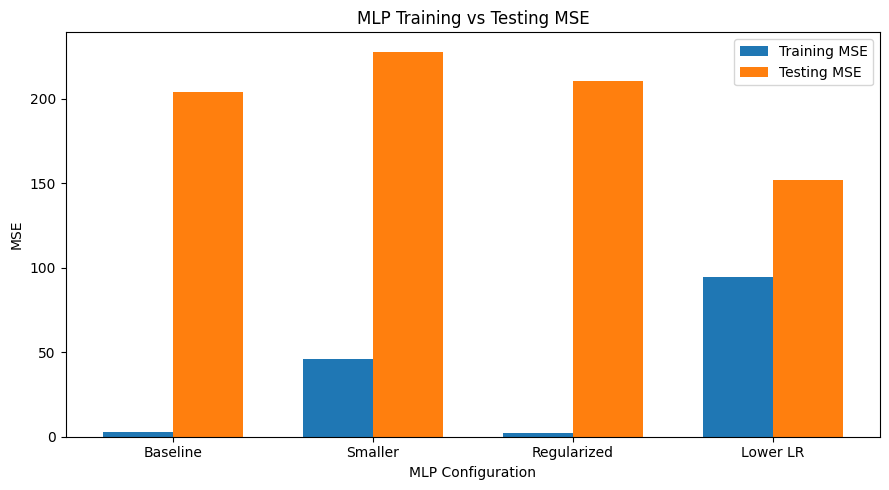

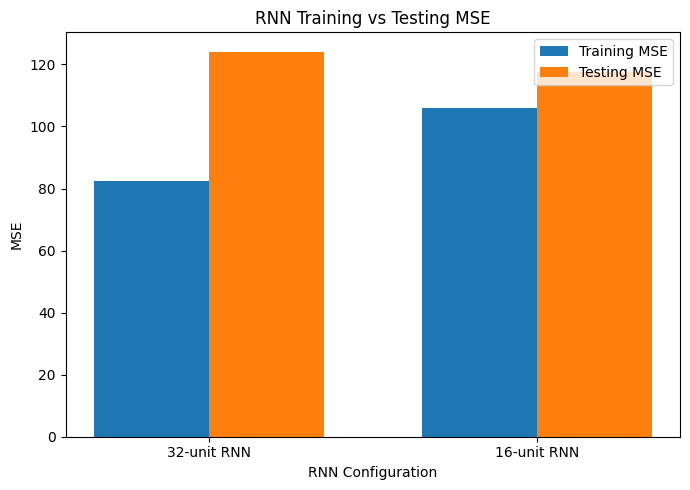

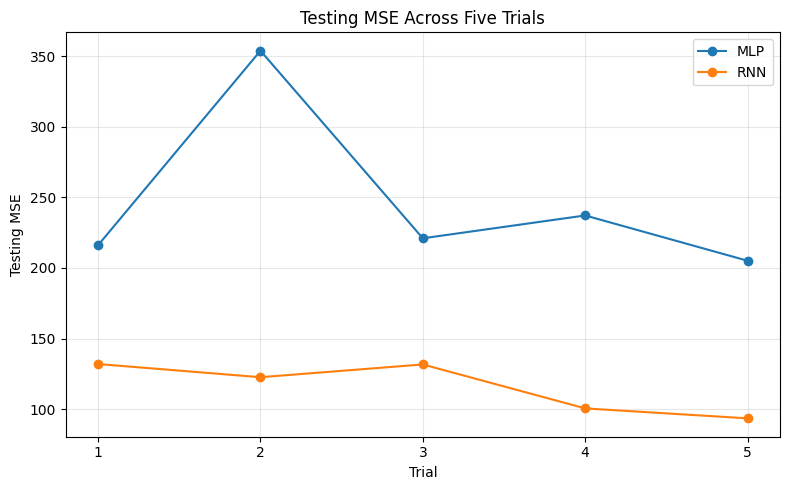

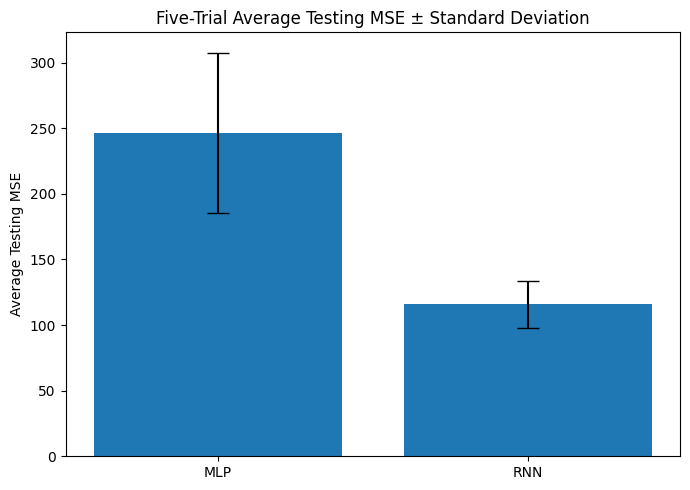

In [3]:
# MGS 670 Project 1: Visual comparison of MLP, RNN, and five-trial model performance.

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 5))
x = np.arange(len(mlp_results))
width = 0.35

plt.bar(x - width/2, mlp_results['Train MSE'], width, label='Training MSE')
plt.bar(x + width/2, mlp_results['Test MSE'], width, label='Testing MSE')

plt.xticks(
    x,
    ['Baseline', 'Smaller', 'Regularized', 'Lower LR']
)
plt.ylabel('MSE')
plt.xlabel('MLP Configuration')
plt.title('MLP Training vs Testing MSE')
plt.legend()
plt.tight_layout()
plt.show()


plt.figure(figsize=(7, 5))
x = np.arange(len(rnn_results))
width = 0.35

plt.bar(x - width/2, rnn_results['Train MSE'], width, label='Training MSE')
plt.bar(x + width/2, rnn_results['Test MSE'], width, label='Testing MSE')

plt.xticks(
    x,
    ['32-unit RNN', '16-unit RNN']
)
plt.ylabel('MSE')
plt.xlabel('RNN Configuration')
plt.title('RNN Training vs Testing MSE')
plt.legend()
plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    mlp_trials_df['Trial'],
    mlp_trials_df['Test MSE'],
    marker='o',
    label='MLP'
)

plt.plot(
    rnn_trials_df['Trial'],
    rnn_trials_df['Test MSE'],
    marker='o',
    label='RNN'
)

plt.xticks([1, 2, 3, 4, 5])
plt.xlabel('Trial')
plt.ylabel('Testing MSE')
plt.title('Testing MSE Across Five Trials')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


plt.figure(figsize=(7, 5))

models = ['MLP', 'RNN']

average_test = [
    mlp_trials_df['Test MSE'].mean(),
    rnn_trials_df['Test MSE'].mean()
]

test_std = [
    mlp_trials_df['Test MSE'].std(),
    rnn_trials_df['Test MSE'].std()
]

plt.bar(
    models,
    average_test,
    yerr=test_std,
    capsize=8
)

plt.ylabel('Average Testing MSE')
plt.title('Five-Trial Average Testing MSE ± Standard Deviation')
plt.tight_layout()
plt.show()

In [4]:
# Outlier analysis: IQR-based screening of continuous admission features before retaining clinically plausible extreme observations.

continuous_features = [
    'age', 'height', 'weight',
    'systolic_blood_pressure', 'diastolic_blood_pressure',
    'heart_rate', 'respiratory_rate', 'oxygen_saturation',
    'temperature', 'motor', 'verbal', 'eye',
    'wbc', 'rbc', 'hemoglobin', 'hematocrit',
    'mcv', 'mch', 'mchc', 'rdw', 'platelet_count',
    'aptt_aptr', 'pt', 'alt', 'ast', 'serum_creatinine',
    'sodium', 'potassium', 'total_serum_bilirubin',
    'lactate', 'inr', 'd_dimer', 'crp'
]

outlier_results = []

for col in continuous_features:
    if col in mlp_df.columns:
        values = pd.to_numeric(mlp_df[col], errors='coerce').dropna()

        if len(values) > 0:
            q1 = values.quantile(0.25)
            q3 = values.quantile(0.75)
            iqr = q3 - q1

            lower = q1 - 1.5 * iqr
            upper = q3 + 1.5 * iqr

            n_outliers = ((values < lower) | (values > upper)).sum()

            outlier_results.append({
                'Feature': col,
                'Lower Bound': lower,
                'Upper Bound': upper,
                'Outliers': n_outliers,
                'Outlier %': (n_outliers / len(values)) * 100
            })

outlier_df = pd.DataFrame(outlier_results)

print("=" * 70)
print("IQR OUTLIER ANALYSIS")
print("=" * 70)

print(
    outlier_df
    .sort_values('Outliers', ascending=False)
    .round(3)
    .to_string(index=False)
)

print("\nTotal features checked:", len(outlier_df))
print(
    "Features containing IQR outliers:",
    (outlier_df['Outliers'] > 0).sum()
)

print(
    "\nDecision: Potential outliers were identified using the 1.5×IQR rule. "
    "They were not automatically removed because extreme clinical measurements "
    "may represent genuinely severe patient conditions rather than data-entry "
    "errors. StandardScaler and training-only preprocessing were retained for "
    "model preparation."
)

IQR OUTLIER ANALYSIS
                 Feature  Lower Bound  Upper Bound  Outliers  Outlier %
                  verbal        5.000        5.000        68     13.439
        serum_creatinine        8.500      188.500        39      7.708
                     inr        0.850        1.250        35     11.111
   total_serum_bilirubin       -0.500       19.500        33      8.189
                  sodium      125.500      145.500        32      6.324
       oxygen_saturation       86.000      102.000        31      6.102
                     mch       22.750       34.350        30      5.929
                      pt       10.650       16.650        28      8.889
                     mcv       71.050      101.850        28      5.534
                     alt      -26.000      110.000        28      6.948
                   motor        6.000        6.000        27      5.336
                     rdw       10.100       17.300        26      5.138
                     ast      -19.500      